In [63]:
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt

In [64]:
class Detector():
    def __init__(self, R: float, N: int, r: float, a: float):
        """
        Parameters
        ----------
        R : float
            Радиус детектора в метрах.
        N : int
            Количество фотоумножителей.
        r : float
            Радиус фотокатода в метрах.
        a : float
            Эффективность фотокатода.
        """
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.rng = np.random.default_rng()

    def coord_cart(self, theta: float, phi: float) -> np.ndarray:
        return np.array([self.R * np.sin(theta)*np.cos(phi), self.R * np.sin(theta)*np.sin(phi), self.R*np.cos(theta)])

    def fill_detector(self):
        self.photo_multipliers = np.zeros((self.N, 3))
        S = 4 * self.R**2 * np.pi 
        delta_S = S / self.N 
        lin_size = delta_S**0.5 
        N_theta = np.pi * self.R / lin_size 
        delta_theta = np.pi / N_theta

        theta_floor = [int(np.floor(N_theta)), np.pi / np.floor(N_theta), delta_theta - np.pi / np.floor(N_theta)]
        theta_ceil = [int(np.ceil(N_theta)), np.pi / np.ceil(N_theta), delta_theta - np.pi / np.ceil(N_theta)]

        best_theta = min(theta_floor, theta_ceil, key=lambda x: abs(x[2]))
        N_theta, delta_theta = best_theta[0], best_theta[1]
        self.delta_theta = delta_theta

        mid_thetas = np.array([delta_theta / 2 + delta_theta*i for i in range(0, N_theta)])
        self.thetas = mid_thetas
        n_phi = np.array([(np.pi * self.N)**0.5*np.sin(theta) for theta in mid_thetas])

        A = self.N / sum([np.sin(theta) for theta in mid_thetas])
        n_phi = np.rint(np.array([A * np.sin(theta) for theta in mid_thetas])) #-> (3, 7, 10, 10, 7, 3)
        #n_phi = np.array([2, 7, 11, 11, 7, 2])  
        self.n_phis = n_phi.astype(int) 
        self.detectors_before = np.zeros(N_theta).astype(int)
        n = 0
        for i in range(N_theta):
            self.detectors_before[i] = n
            n += n_phi[i]

        phi_phases = np.zeros(N_theta)
        for i in range(N_theta):
            if i == 0:
                continue
            phi_phases[i] = np.pi / np.lcm(int(n_phi[i-1]), int(n_phi[i]))
        self.phis = np.zeros(N_theta)
        n = 0
        phase = 0
        for i in range(N_theta):
            if i < N_theta/2:
                phase += phi_phases[i]
            else:
                phase -= phi_phases[i]
            self.phis[i] = phase
            for j in range(int(n_phi[i])):
                self.photo_multipliers[n] = self.coord_cart(mid_thetas[i], 2*np.pi/n_phi[i] * j + phase)
                n += 1

In [65]:
class Source:
    def __init__(self, pos : np.ndarray, E : float, decay_length : float):
        """
        Parameters
        ----------
        pos : np.array
            координаты источника
        """
        self.Y = 10000 
        self.E = E
        self.pos = pos
        self.decay_lenght = decay_length

In [66]:
detector = Detector(R=2, N=40, r=0.1, a=0.5)
detector.fill_detector()
src_pos = np.array([0, 0, 0])
source = Source(src_pos, 1, 0)

In [67]:
with pm.Model() as model:
    n_photons = int(source.E * source.Y)
    phi = pm.Uniform("phi", lower=0, upper=2*np.pi, shape=n_photons)
    cos_theta = pm.Uniform("cos_theta", lower=-1, upper=1, shape=n_photons)
    sin_theta = pt.sqrt(1 - cos_theta**2)
    photons_directions = pt.stack([sin_theta * pt.cos(phi), sin_theta * pt.sin(phi), cos_theta], axis=1)

    nr = photons_directions @ source.pos
    r2 = pt.dot(source.pos, source.pos)

    t = -nr + np.sqrt(nr**2 - (r2 - detector.R**2))
    if source.decay_lenght == 0:
        survived = pt.ones_like(t, dtype="int64")
    else:
        exps = pt.exp(-t / source.decay_lenght)
        survived = pm.Bernoulli("survived", p=exps)

    hits = source.pos + photons_directions * t[:, None]

    hits_thetas = pt.arccos(hits[:, 2] / detector.R)
    hits_phis = pt.arctan2(hits[:, 1], hits[:, 0])

    theta_indices = pt.clip(pt.floor(hits_thetas / detector.delta_theta).astype("int64"), 0, len(detector.n_phis) - 1)

    n_phis = pt.as_tensor_variable(detector.n_phis)
    phis = pt.as_tensor_variable(detector.phis)
    detectors_before = pt.as_tensor_variable(detector.detectors_before)
    photo_multipliers = pt.as_tensor_variable(detector.photo_multipliers)

    phi_indices = (pt.round(n_phis[theta_indices] / (2 * np.pi) * (hits_phis - phis[theta_indices])).astype("int64") % n_phis[theta_indices])

    photo_multiplier_ids = detectors_before[theta_indices] + phi_indices
    photo_multiplier_coords = photo_multipliers[photo_multiplier_ids]

    distances2 = pt.sum((hits - photo_multiplier_coords)**2, axis=1)
    registered = distances2 <= detector.r**2

    n_detected = pt.sum(pt.cast(registered, "int64") * survived)

    charge = pm.Poisson("charge", mu=detector.a * n_detected)
    

Sampling: [charge, cos_theta, phi]


Средний заряд: 124.185
Стандартное отклонение: 13.652720424882363


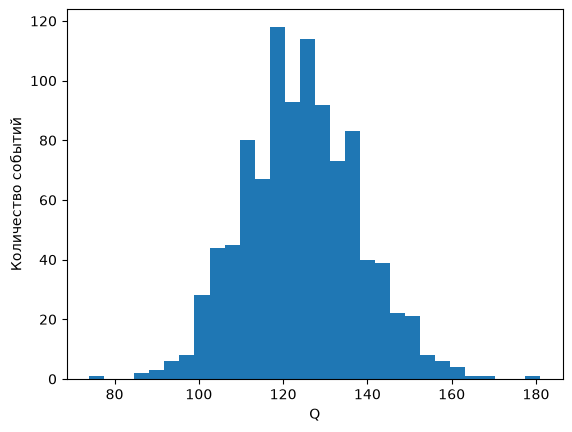

In [68]:
with model:
    samples = pm.sample_prior_predictive(draws=1000, var_names=["charge"], return_inferencedata=False)

charges = samples["charge"]

print("Средний заряд:", np.mean(charges))
print("Стандартное отклонение:", np.std(charges))

plt.hist(charges, bins=30)
plt.xlabel("Q")
plt.ylabel("Количество событий")
plt.show()

Из 4 задания. Среднее и стандартное отклонение совпадают

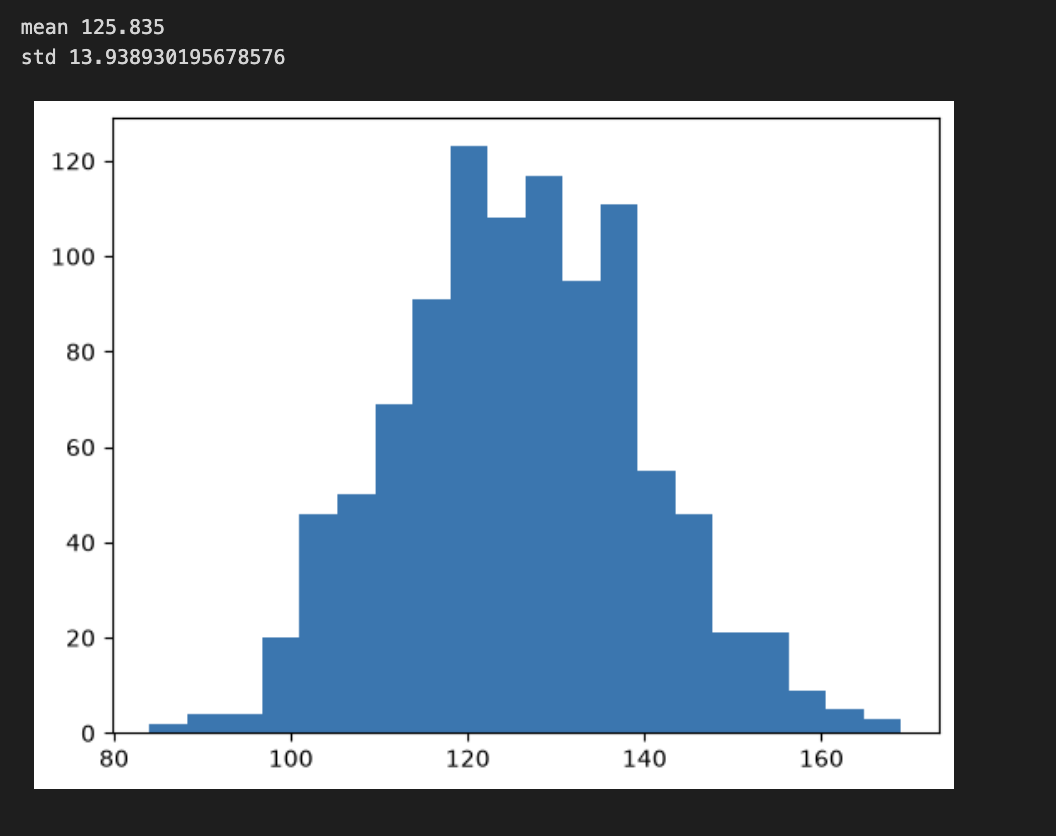